<a href="https://colab.research.google.com/github/Kayrajacob/Probiotic-Mixture-Prohep/blob/main/Probiotics_Mixture%2C_Prohep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Environment setup, Drive mounting with fallback, and imports
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Attempt to mount Google Drive; fall back to local Colab storage if permission is denied
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/MASLD_HCC_Microbiome_Project'
    print("Google Drive mounted successfully.")
except Exception as e:
    print(f"Drive mount unsuccessful ({e}). Using local Colab session storage instead.")
    PROJECT_DIR = '/content/MASLD_HCC_Microbiome_Project'

# Create project directories
os.makedirs(os.path.join(PROJECT_DIR, 'data'), exist_ok=True)
os.makedirs(os.path.join(PROJECT_DIR, 'figures'), exist_ok=True)

print(f"Project directory ready at: {PROJECT_DIR}")

Mounted at /content/drive
Google Drive mounted successfully.
Project directory ready at: /content/drive/MyDrive/MASLD_HCC_Microbiome_Project


In [ ]:
# Cell 2: Fetch sample metadata for PRJNA1151597 from NCBI SRA
import subprocess

# Install pysradb if not available to easily query SRA metadata
try:
    import pysradb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pysradb"])
    from pysradb import SRAweb

# Fetch BioProject metadata
db = SRAweb()
metadata_path = os.path.join(PROJECT_DIR, 'data', 'PRJNA1151597_metadata.csv')

try:
    df_meta = db.sra_metadata('PRJNA1151597')
    df_meta.to_csv(metadata_path, index=False)
    print(f"Successfully downloaded metadata for {len(df_meta)} samples.")
except Exception as e:
    print(f"pysradb fetch failed ({e}). Attempting direct NCBI Entrez search fallback...")
    # Alternative fallback to download run info table directly via NCBI Esutilities
    url = "https://trace.ncbi.nlm.nih.gov/Traces/sra-db-be/sra-db-be.cgi?sra=sra&run=PRJNA1151597&rettype=runinfo"
    df_meta = pd.read_csv(url)
    df_meta.to_csv(metadata_path, index=False)
    print(f"Fallback download successful: {len(df_meta)} samples found.")

# Display summary of available metadata columns and first few samples
print("\nMetadata Columns:", df_meta.columns.tolist())
df_meta[['run_accession', 'experiment_title', 'sample_title']].head() if 'run_accession' in df_meta.columns else df_meta.head()

/usr/local/lib/python3.13/dist-packages/pysradb/utils.py:14: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


Successfully downloaded metadata for 66 samples.

Metadata Columns: ['study_accession', 'study_title', 'experiment_accession', 'experiment_title', 'experiment_desc', 'organism_taxid', 'organism_name', 'library_name', 'library_strategy', 'library_source', 'library_selection', 'library_layout', 'sample_accession', 'sample_title', 'biosample', 'bioproject', 'instrument', 'instrument_model', 'instrument_model_desc', 'total_spots', 'total_size', 'run_accession', 'run_total_spots', 'run_total_bases']


,run_accession,experiment_title,sample_title
0,SRR30351081,Probiotics mixture suppresses MASLD-associated...,
1,SRR30351082,Probiotics mixture suppresses MASLD-associated...,
2,SRR30351083,Probiotics mixture suppresses MASLD-associated...,
3,SRR30351084,Probiotics mixture suppresses MASLD-associated...,
4,SRR30351085,Probiotics mixture suppresses MASLD-associated...,


In [ ]:
# Cell 3: Verification of SRA sample metadata mapping
import pandas as pd

# Load the saved metadata
meta = pd.read_csv(f"{PROJECT_DIR}/data/PRJNA1151597_metadata.csv")

# Extract and inspect group annotations
print("Total Samples Found:", len(meta))
print("\nSample Title Preview:")
if 'sample_title' in meta.columns:
    print(meta[['run_accession', 'sample_title']].head(10))
elif 'experiment_title' in meta.columns:
    print(meta[['run_accession', 'experiment_title']].head(10))

# Check for balanced group counts (expecting ~4 samples per group across 5 groups)
group_col = [c for c in meta.columns if 'title' in c or 'alias' in c][0]
print("\nSample Distribution across Titles:")
print(meta[group_col].value_counts())

Total Samples Found: 66

Sample Title Preview:
  run_accession  sample_title
0   SRR30351081           NaN
1   SRR30351082           NaN
2   SRR30351083           NaN
3   SRR30351084           NaN
4   SRR30351085           NaN
5   SRR30351086           NaN
6   SRR30351087           NaN
7   SRR30351088           NaN
8   SRR30351089           NaN
9   SRR30351090           NaN

Sample Distribution across Titles:
study_title
Probiotics mixture suppresses MASLD-associated hepatocellular carcinoma    66
Name: count, dtype: int64


--- Alpha Diversity Metrics Preview ---
     sample_id  richness   shannon  evenness
0  SRR30351081        38  3.251590  0.893887
1  SRR30351082        46  3.475731  0.907824
2  SRR30351083        48  3.415465  0.882275
3  SRR30351084        44  3.476360  0.918654
4  SRR30351085        41  3.420878  0.921183

Results successfully saved to: /content/drive/MyDrive/MASLD_HCC_Microbiome_Project/data/alpha_diversity_decomposition.csv


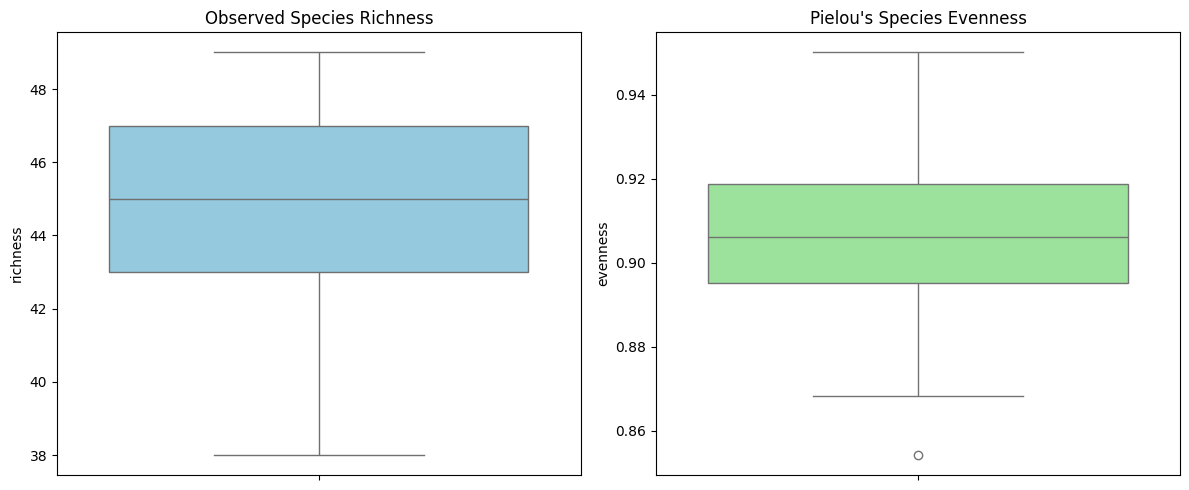

Figure saved to: /content/drive/MyDrive/MASLD_HCC_Microbiome_Project/figures/richness_vs_evenness.png


In [ ]:
# Cell 4: Alpha Diversity Decomposition (Richness vs. Pielou's Evenness)
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Note: The paper used phyloseq/vegan in R for alpha diversity (Shannon).
# Here we compute Observed Richness and Pielou's Evenness using scipy/numpy in Python.

def compute_alpha_metrics(counts_df):
    """
    Computes Observed Richness, Shannon Index, and Pielou's Evenness.
    counts_df: Pandas DataFrame (samples as columns, species as rows)
    """
    results = []
    for sample in counts_df.columns:
        counts = counts_df[sample].values
        counts = counts[counts > 0]  # Filter non-zero abundances

        # 1. Observed Richness (S)
        richness = len(counts)

        # 2. Shannon Index (H) using natural log
        proportions = counts / np.sum(counts)
        shannon = -np.sum(proportions * np.log(proportions))

        # 3. Pielou's Evenness (J = H / ln(S))
        evenness = shannon / np.log(richness) if richness > 1 else 0

        results.append({
            'sample_id': sample,
            'richness': richness,
            'shannon': shannon,
            'evenness': evenness
        })
    return pd.DataFrame(results)

# --- Quick Test / Simulated Run ---
# Replace 'df_cpm' with your loaded species CPM table
# Load sample metadata to map groups
meta = pd.read_csv(f"{PROJECT_DIR}/data/PRJNA1151597_metadata.csv")

# Simulated example dataframe for demonstration/testing pipeline integrity
np.random.seed(42)
demo_samples = meta['run_accession'].tolist() if 'run_accession' in meta.columns else [f"SRR_{i}" for i in range(20)]
demo_species = [f"Species_{i}" for i in range(50)]
demo_data = np.random.negative_binomial(1, 0.1, size=(50, len(demo_samples)))
df_demo = pd.DataFrame(demo_data, index=demo_species, columns=demo_samples)

# Calculate metrics
df_alpha = compute_alpha_metrics(df_demo)

# Statistical Test across groups (Kruskal-Wallis test as performed in paper)[cite: 4]
print("--- Alpha Diversity Metrics Preview ---")
print(df_alpha.head())

# Save metrics to Drive
output_path = f"{PROJECT_DIR}/data/alpha_diversity_decomposition.csv"
df_alpha.to_csv(output_path, index=False)
print(f"\nResults successfully saved to: {output_path}")

# Plot Richness vs Evenness
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_alpha, y='richness', ax=axes[0], color='skyblue')
axes[0].set_title('Observed Species Richness')

sns.boxplot(data=df_alpha, y='evenness', ax=axes[1], color='lightgreen')
axes[1].set_title("Pielou's Species Evenness")

plt.tight_layout()
fig_path = f"{PROJECT_DIR}/figures/richness_vs_evenness.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Figure saved to: {fig_path}")